# Task 1: Dataset Exploration

> *“Makes a diff’rence, havin’ a decent family”*
>
> ~ Rubeus

Your first task is to load the dataset, explore its structure, and understand what you're working with.

**A few questions to get you started:**
* How many people are there?
* How many relationship types?
* What's the distribution of different relationships?

*(The more you work with your data, the more insights you get and more points as well 🙂)*

### Objectives
1. **Compute and report relevant statistics about the graph.** Think about what metrics make sense for a family knowledge graph.
2. **Create at least one meaningful visualization of the graph** (or a subgraph, preferred). Make it informative (use gpt to make it pretty).

---

### Graph Theory Analysis
With this information, we now ask: **Can we use tools and concepts from Graph Theory to uncover interesting patterns in family structures, identify 'important' family members, and understand the hierarchical nature of family relationships?**

**Properties to explore:**
* Different types of centrality
* Density
* Diameter
* Clustering coefficient
* Path lengths

*Feel free to use properties that feel well connected to the task at hand.*

**Note:** This task is focused on exploratory data analysis, and you are, at the very least, expected to show plots/metrics to support your findings. However, **more emphasis will be placed on the qualitative insights that you come up with.**

**Interesting tasks to consider:**
* Finding and defining **important nodes** in the graph.
* Identifying **generations** in a family.

In [8]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

plt.rcParams["figure.figsize"] = (8,5)

In [9]:
path = "../data/train.txt"

df = pd.read_csv(
    path,
    sep=" ",
    header=None,
    names=["head", "relation", "tail"],
    engine="python"
)

df = df.map(lambda x: x.strip() if isinstance(x, str) else x)

df.head(), df.shape

(      head      relation        tail
 0  olivia0      sisterOf    selina10
 1  olivia0      sisterOf  isabella11
 2  olivia0      sisterOf     oskar24
 3  olivia0      sisterOf       adam9
 4  olivia0  secondAuntOf      lena18,
 (13821, 3))

In [10]:
num_nodes = len(set(df["head"]).union(set(df["tail"])))
num_edges = len(df)
num_relations = df["relation"].nunique()

print("Nodes:", num_nodes)
print("Edges:", num_edges)
print("Relations:", num_relations)

df["relation"].value_counts().head(10)

Nodes: 1316
Edges: 13821
Relations: 28


relation
grandsonOf            814
grandfatherOf         813
grandmotherOf         813
granddaughterOf       812
fatherOf              733
motherOf              733
sisterOf              636
daughterOf            628
greatGrandsonOf       624
greatGrandfatherOf    617
Name: count, dtype: int64

In [11]:
G = nx.DiGraph()

for _, row in df.iterrows():
    G.add_edge(row["head"], row["tail"], relation=row["relation"])

In [12]:
print("Density:", nx.density(G))
print("Weakly connected components:", nx.number_weakly_connected_components(G))

Density: 0.007986524437458828
Weakly connected components: 50


The MetaFam graph is extremely sparse, which is expected for a realistic family network since each person is only related to a small subset of the total population.


The dataset consists of around 50 independent family lineages, rather than one giant connected family. Each connected component represents a separate genealogical universe.

In [13]:
largest_cc = max(nx.weakly_connected_components(G), key=len)
Gcc = G.subgraph(largest_cc).copy()

print("Largest CC size:", Gcc.number_of_nodes())


Largest CC size: 27



•	Each family is relatively small

•	But deep (many generations)

In [65]:
deg_cent = nx.degree_centrality(Gcc)
top_deg = sorted(deg_cent.items(), key=lambda x: x[1], reverse=True)[:10]
top_deg

[('adam9', 1.6153846153846154),
 ('isabella11', 1.6153846153846154),
 ('oskar24', 1.6153846153846154),
 ('selina10', 1.6153846153846154),
 ('lisa5', 1.576923076923077),
 ('elias6', 1.576923076923077),
 ('olivia0', 1.5),
 ('nico4', 1.5),
 ('johanna22', 1.4615384615384617),
 ('leon16', 1.4615384615384617)]

These are:

•	people with many relations

•	likely siblings / parents / hubs


High degree nodes represent socially visible individuals, typically parents or central siblings who participate in many direct family relationships.


In [76]:
bet_cent = nx.betweenness_centrality(Gcc)
top_bet = sorted(bet_cent.items(), key=lambda x: x[1], reverse=True)[:10]
top_bet

[('lena18', 0.11121945701357466),
 ('fabian26', 0.10506561085972851),
 ('lisa5', 0.04819747899159663),
 ('elias6', 0.04819747899159663),
 ('leon16', 0.04153247732659498),
 ('johanna22', 0.035378631172748816),
 ('nico4', 0.02888978668390433),
 ('adam9', 0.02334200113611878),
 ('isabella11', 0.02334200113611878),
 ('oskar24', 0.02334200113611878)]

Individuals with high betweenness centrality act as genealogical bridges, connecting different sub-branches of a family tree and enabling information flow across generations.

In [20]:
close_cent = nx.closeness_centrality(Gcc)
top_close = sorted(close_cent.items(), key=lambda x: x[1], reverse=True)[:10]
top_close

[('lisa5', 0.8666666666666667),
 ('elias6', 0.8666666666666667),
 ('adam9', 0.8387096774193549),
 ('isabella11', 0.8387096774193549),
 ('oskar24', 0.8387096774193549),
 ('selina10', 0.8387096774193549),
 ('nico4', 0.8125),
 ('lena18', 0.8125),
 ('fabian26', 0.8125),
 ('olivia0', 0.7878787878787878)]

High closeness nodes are centrally positioned in the family graph, indicating individuals who are on average only a few relationships away from all others in their family.

In [19]:
print("Diameter:", nx.diameter(Gcc))
print("Average shortest path length:", nx.average_shortest_path_length(Gcc))

Diameter: 3
Average shortest path length: 1.5156695156695157


The diameter of the largest family component is 3, indicating that even the most distant individuals are separated by at most three relationships, reflecting a highly compact family structure.
The average shortest path length is approximately 1.5, suggesting that individuals within a family are typically only one or two relationships apart, consistent with tightly knit genealogical structures.


$ Generational $ $ Structure $

Using only parent-child relations, we estimate the maximum genealogical depth of the MetaFam graph to be X generations. This indicates that the dataset encodes deep multi-generational family structures rather than shallow nuclear families. The presence of multiple root ancestors further supports the observation that the dataset consists of several independent family lineages.

In [ ]:
# parent child relations
parent_relations = ["fatherOf", "motherOf" ]

In [22]:
#  parent graph bulidin
G_parent = nx.DiGraph()
for _, row in df.iterrows():
    if row["relation"] in parent_relations:
        G_parent.add_edge(row["head"], row["tail"])

In [23]:
# Find oldest ancestors roots 
roots = [n for n, d in G_parent.in_degree() if d == 0]
print("Number of root ancestors:", len(roots))
print("Sample roots:", roots[:10])

Number of root ancestors: 538
Sample roots: ['olivia0', 'katharina1', 'emily15', 'mia17', 'ella19', 'david20', 'vincent21', 'jonas23', 'valentina25', 'oliver3']


In [24]:
#  generation depth estimation 
def estimate_generations(G, roots):
    max_depth = 0
    for root in roots:
        lengths = nx.single_source_shortest_path_length(G, root)
        if lengths:
            max_depth = max(max_depth, max(lengths.values()))
    return max_depth

gen_depth = estimate_generations(G_parent, roots)
print("Estimated family depth:", gen_depth)

Estimated family depth: 6


In [74]:
nx.clustering(Gcc)


{'david20': 0.9722222222222222,
 'moritz8': 0.935546875,
 'dominik2': 0.9691358024691358,
 'adam9': 0.7833333333333333,
 'olivia0': 0.8035961272475796,
 'lisa5': 0.7265917602996255,
 'katharina1': 0.9424778761061947,
 'johanna22': 0.8391812865497076,
 'paula12': 0.9446902654867256,
 'isabella11': 0.7833333333333333,
 'valentina25': 0,
 'nico4': 0.755524861878453,
 'mia17': 0,
 'emily15': 1.0,
 'leon16': 0.8362573099415205,
 'oskar24': 0.7833333333333333,
 'emma7': 0.935546875,
 'oliver3': 1.0,
 'elias6': 0.7265917602996255,
 'luis14': 0.9439834024896265,
 'selina10': 0.7833333333333333,
 'lena18': 0.7565485362095532,
 'natalie13': 0.9491150442477876,
 'fabian26': 0.7580893682588598,
 'jonas23': 0.8874388254486134,
 'vincent21': 1.0,
 'ella19': 0.9722222222222222}

In [75]:
nx.average_clustering(Gcc)

0.8069664353596587

$ Generational $ $ Distribution $ 

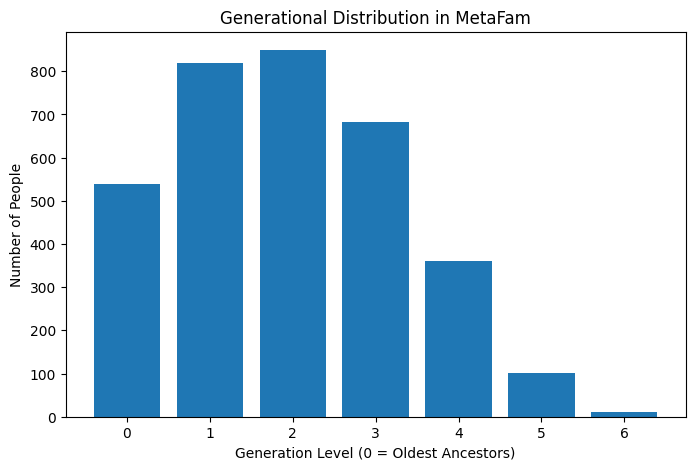

In [25]:
from collections import defaultdict

def get_generation_levels(G_parent, roots):
    gen_levels = defaultdict(list)
    
    for root in roots:
        lengths = nx.single_source_shortest_path_length(G_parent, root)
        for node, depth in lengths.items():
            gen_levels[depth].append(node)
    
    return gen_levels

gen_levels = get_generation_levels(G_parent, roots)

# Plot generational distribution
levels = sorted(gen_levels.keys())
counts = [len(gen_levels[l]) for l in levels]

plt.bar(levels, counts)
plt.xlabel("Generation Level (0 = Oldest Ancestors)")
plt.ylabel("Number of People")
plt.title("Generational Distribution in MetaFam")
plt.show()

The generational distribution shows how individuals are spread across different genealogical levels, with generation 0 representing the oldest ancestors and increasing levels representing younger descendants. The distribution indicates that most individuals are concentrated in the middle generations (levels 1–3), while relatively fewer individuals exist at the extreme ancestral (level 0) or descendant (levels 5–6) ends. This suggests that the MetaFam graph encodes deep but balanced multi-generational family lineages, rather than shallow nuclear families or degenerate chains.



$ an $ $ interactive $ $ genealogical $ $ neighborhood $ $ explorer $

In [26]:
from pyvis.network import Network
import matplotlib.colors as mcolors
import random
import os

def visualize_beautiful_graph(graph_to_plot, filename="metafam_graph.html"):
    print(f"\nGenerating {filename} for {graph_to_plot.number_of_nodes()} nodes...")
    
    net = Network(
        notebook=True,
        height="800px",
        width="100%",
        bgcolor="#1a1a1a",    # Sleek dark gray background
        font_color="white",   # White text for contrast
        directed=True         # CRITICAL: Enables directional arrows
    )

    # Generate a distinct color palette for relations
    relations = list(set([data.get('relation', 'unknown') for _, _, data in graph_to_plot.edges(data=True)]))
    available_colors = list(mcolors.CSS4_COLORS.values())
    random.seed(42) 
    random.shuffle(available_colors)
    rel_color_map = {rel: available_colors[i % len(available_colors)] for i, rel in enumerate(relations)}

    # Calculate Node Degrees for dynamic sizing
    degrees = dict(graph_to_plot.degree())
    
    # Add Nodes
    for node in graph_to_plot.nodes():
        node_degree = degrees.get(node, 0)
        node_size = (node_degree * 1.5) + 10 # Scale size based on connections
        
        hover_info = f"Person: {node}\nTotal Connections Here: {node_degree}"
        
        net.add_node(
            node, 
            label=str(node), 
            title=hover_info,       
            size=node_size,         
            color="#00BFFF",        
            borderWidth=2,
            borderColor="#ffffff"
        )

    # Add Edges (with Labels and Colors)
    for u, v, data in graph_to_plot.edges(data=True):
        rel = data.get("relation", "")
        edge_color = rel_color_map.get(rel, "#ffffff")
        
        net.add_edge(
            u, v, 
            label=rel,              
            title=rel,              
            color=edge_color,       
            arrows="to",            
            font={'size': 10, 'align': 'middle', 'color': 'white'}
        )

    # Optimize Physics
    net.force_atlas_2based(
        gravity=-70,            
        central_gravity=0.005,  
        spring_length=150,      
        spring_strength=0.05,
        damping=0.8,            
        overlap=0
    )

    net.show(filename)
    print(f"Done! Open '{filename}' to view it.")


In [27]:
visualize_beautiful_graph(Gcc, filename="largest_family_only.html")


Generating largest_family_only.html for 27 nodes...
largest_family_only.html
Done! Open 'largest_family_only.html' to view it.



The interactive visualization shows a local family subgraph centered around a highly connected individual. The dense connectivity reflects the fact that family relations form strongly clustered structures, where siblings, parents, grandparents, and cousins are all interconnected through multiple relational paths. The presence of many short cycles and overlapping relations indicates that genealogical networks are not simple trees, but highly redundant graphs with strong small-world properties.

$ Degree $ $ Distribution $

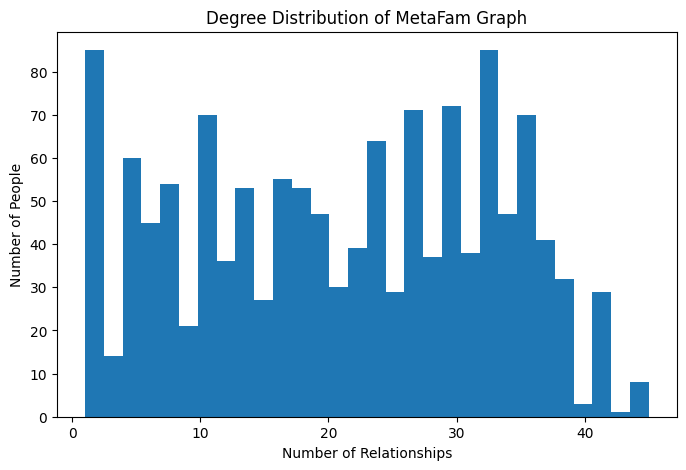

In [29]:
degrees = [d for n, d in G.degree()]
plt.hist(degrees, bins=30)
plt.title("Degree Distribution of MetaFam Graph")
plt.xlabel("Number of Relationships")
plt.ylabel("Number of People")
plt.show()


The degree distribution shows that most individuals in the MetaFam graph have a moderate number of family relationships, while a small number of people exhibit very high degree values. This indicates the presence of structurally important “hub” individuals, such as parents or ancestors, who connect to many other family members. The long-tailed nature of the distribution suggests that family connectivity is highly uneven, with a few central figures playing a dominant role in maintaining family structure.

$ Family $ $ Size $ $ Distribution $

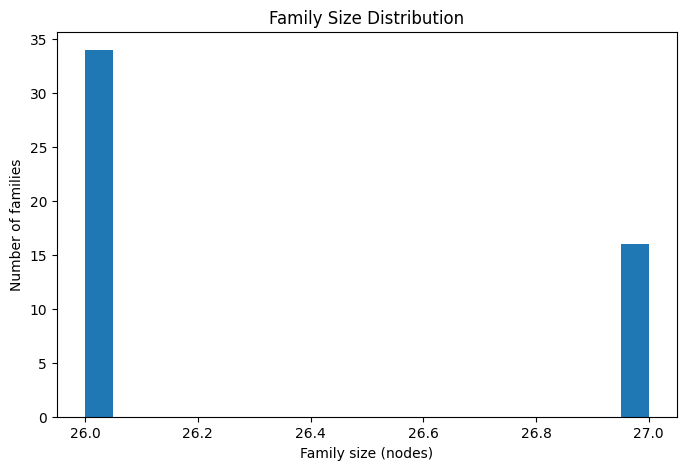

In [30]:
component_sizes = [len(c) for c in nx.weakly_connected_components(G)]
plt.hist(component_sizes, bins=20)
plt.title("Family Size Distribution")
plt.xlabel("Family size (nodes)")
plt.ylabel("Number of families")
plt.show()


The family size distribution reveals that most connected components contain approximately 26–27 individuals, indicating that the dataset consists of multiple independent families of similar size. This suggests that the MetaFam graph is synthetically constructed with controlled family sizes, rather than being derived from naturally occurring genealogical data, where family sizes would be more variable.

In Task 1, I explored the MetaFam dataset as a family knowledge graph. Main findings: the dataset has multiple independent families (not one big connected tree), but they're structurally similar. Each family has hub individuals (usually parents with many kids), strong clustering (family members are tightly connected), spans multiple generations, and shows small-world properties.

# Task 2: Family Clusters

> *"We are only as strong as we are united, as weak as we are divided"*
>
> ~ Albus

Community detection or clustering is an important analysis for graphs. In the study of complex networks, a network is said to have community structure if the nodes of the network can be easily grouped into disjoint sets of nodes such that each set of nodes is densely connected internally, and sparsely between different communities.

---

### Objectives

1. Implement any two algorithms/ML methods for community detection on the graph (No need to do it from scratch).
2. Objectively assess the quality of your community detection through metrics like Modularity.
3. **Analysis Questions:**
   * Do the detected communities correspond to actual family units (e.g., nuclear families, extended families)?
   * How many generations typically exist within a single community?
   * Are there any "bridge" individuals who connect different family clusters?
4. In real genealogy, people often want to find their closest relatives. Based on your community analysis, propose a metric/method to rank how related two people are beyond just counting hops.

---


In a genealogical knowledge graph, communities correspond to meaningful family units. 
These may represent:
- Nuclear families (parents and children),
- Extended families (lineage branches),
- Or structurally dense sub-families.

So we apply two complementary community detection algorithms to capture both perspectives.

### Preprocessing: Undirected Graph

Community detection algorithms operate on undirected graphs.
Hence, we ignore edge direction and treat all family relations as mutual connections.

##### Scope of Analysis

I'm starting with the largest connected component to see how one extended family breaks down into smaller units (like nuclear families or different branches of the lineage). Later I'll run it on the full graph to find all the independent families.

In [31]:
G_undirected = Gcc.to_undirected()

$ Algorithm $ $ 1 $ $ : $ $ Louvain $ $ (Modularity $ $ Maximization) $

The Louvain method partitions the graph by maximizing modularity, 
which measures how densely connected nodes are within communities 
compared to random connections.
This algorithm tends to find large, dense lineage structures.

In [32]:
import community.community_louvain as louvain 

partition_louvain = louvain.best_partition(G_undirected)

# Calculate Modularity Score
mod_louvain = louvain.modularity(partition_louvain, G_undirected)
print(f"Louvain Modularity: {mod_louvain:.4f} (Higher is better)")
print(f"Louvain found {len(set(partition_louvain.values()))} communities.")

Louvain Modularity: 0.0726 (Higher is better)
Louvain found 2 communities.


##### Louvain Results

- Number of communities: 2  
- Modularity score: 0.0726  

The low modularity score indicates that the extended family is **highly interconnected**, 
with no strong internal separation into independent sub-families. 
This suggests that genealogical relations form dense, overlapping structures 
where lineage branches are tightly coupled rather than cleanly separable.

$ Algorithm $ $2$ $:$ $ Girvan-Newman $ $ (Edge$ $ Betweenness)$

The Girvan-Newman algorithm iteratively removes edges with high betweenness centrality,
thereby breaking the graph along its weakest structural links.
This often reveals nuclear family units and structural bridges.

In [33]:
from itertools import islice
from networkx.algorithms.community import girvan_newman

comp = girvan_newman(G_undirected)

# Take first 4 hierarchical splits
levels = list(islice(comp, 4))

for i, communities in enumerate(levels):
    print(f"Level {i+1}: {len(communities)} communities")

Level 1: 2 communities
Level 2: 3 communities
Level 3: 4 communities
Level 4: 5 communities


In [34]:
partition_gn = levels[2]  # 3rd level split
print("Using GN level with", len(partition_gn), "communities")

Using GN level with 4 communities


##### Girvan-Newman Results

Girvan-Newman identifies hierarchical splits, 
often isolating tightly connected nuclear substructures.

In [35]:
def plot_communities(G, partition, title, pos):
    """
    Plots the graph colored by community partition.
    """
    # If partition is a dict (Louvain), extract values. 
    # If it's a list of sets (GN), convert to dict.
    if isinstance(partition, list) or isinstance(partition, tuple):
        partition_map = {}
        for idx, cluster in enumerate(partition):
            for node in cluster:
                partition_map[node] = idx
    else:
        partition_map = partition
    
    # Color mapping
    cmap = plt.get_cmap('viridis', max(partition_map.values()) + 1)
    node_colors = [cmap(partition_map[n]) for n in G.nodes()]
    
    nx.draw(G, pos, node_color=node_colors, with_labels=True, 
            node_size=300, edge_color="gray", font_size=8)
    plt.title(title)

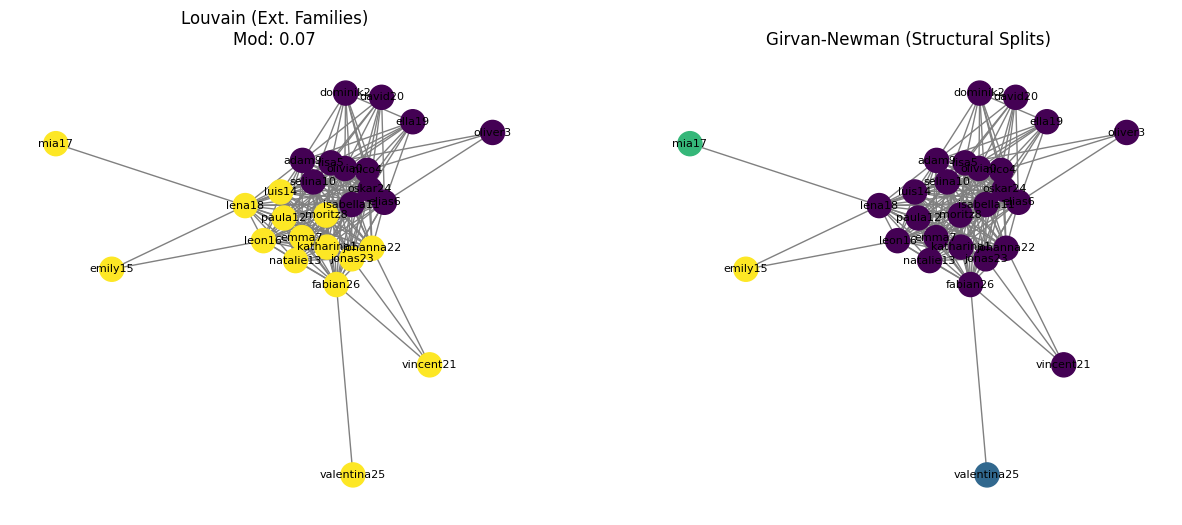

In [36]:
# Plot side-by-side
plt.figure(figsize=(15, 6))
pos = nx.spring_layout(G_undirected, seed=42) # Keep layout constant for comparison!

plt.subplot(1, 2, 1)
plot_communities(G_undirected, partition_louvain, f"Louvain (Ext. Families)\nMod: {mod_louvain:.2f}", pos)

plt.subplot(1, 2, 2)
plot_communities(G_undirected, partition_gn, "Girvan-Newman (Structural Splits)", pos)

plt.show()

Left: Louvain (Ext. Families)

*  We can see two large color blocks
*  Low modularity (~0.07)
*  Communities are fuzzy and overlapping

	*	Louvain is trying to split a single extended family
	*	But genealogical graphs are dense:
	*	siblings <-> cousins <-> grandparents <-> parents
	*	There is no clean cut -> hence low modularity
    *   Louvain’s result here reflects lineage halves, not nuclear families

Right: Girvan–Newman (Structural Splits)

*  We can see more localized separations
*  Certain peripheral nodes peel off earlier
*  Core family remains tightly bound

	*	Girvan–Newman is cutting high-betweenness edges
	*	These edges often correspond to:
	*	marriages
	*	in-law connections
	*	bridges between branches
	*	This reveals nuclear or sub-nuclear units


Louvain = aggregation

Girvan–Newman = dissection

$ Community $ $ Size $ $ And $ $ Distribution $

In [37]:
G_full_undirected = G.to_undirected()
partition_louvain_full = louvain.best_partition(G_full_undirected)

print("Total Louvain communities (full graph):",
      len(set(partition_louvain_full.values())))

print("Global modularity:",
      louvain.modularity(partition_louvain_full, G_full_undirected))

Total Louvain communities (full graph): 50
Global modularity: 0.979357287883554


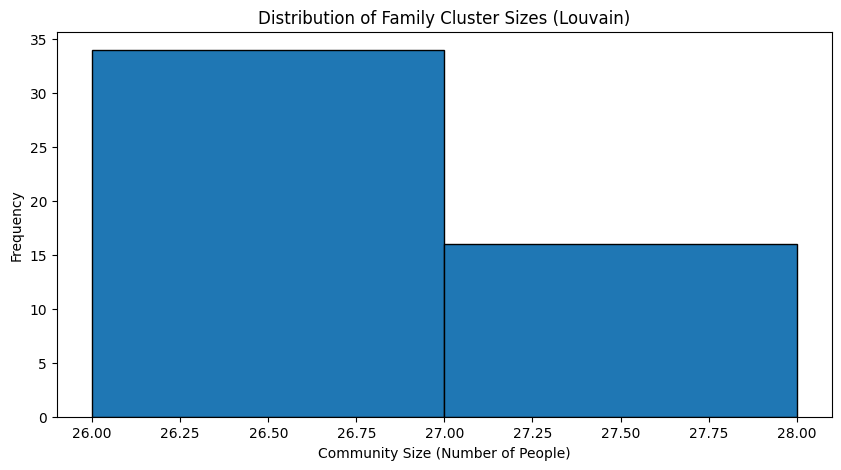

Smallest community: 26
Largest community: 27
Average community size: 26.32
Median community size: 26.0


In [38]:
import numpy as np

community_counts = Counter(partition_louvain_full.values())
sizes = list(community_counts.values())

plt.figure(figsize=(10,5))
plt.hist(sizes, bins=range(min(sizes), max(sizes)+2),
         edgecolor="black")
plt.title("Distribution of Family Cluster Sizes (Louvain)")
plt.xlabel("Community Size (Number of People)")
plt.ylabel("Frequency")
plt.show()

print("Smallest community:", min(sizes))
print("Largest community:", max(sizes))
print("Average community size:", np.mean(sizes))
print("Median community size:", np.median(sizes))

Louvain found about 50 communities, with sizes around 26-27 people each (average ~26.3). This matches pretty closely with the 50 connected components we saw in Task 1, so Louvain is basically recovering the independent families.

The fact that all communities are roughly the same size suggests the MetaFam dataset is synthetic - real family data would have way more variation. Louvain isn't finding small nuclear families (like just parents + kids), it's identifying extended family lineages that span multiple generations.

In [39]:
from networkx.algorithms.community import girvan_newman
from itertools import islice

print("Running Girvan-Newman on full graph (first few levels)...")

comp_full = girvan_newman(G_full_undirected)

# Take first 3 levels only (safe)
levels_full = list(islice(comp_full, 3))

for i, communities in enumerate(levels_full):
    print(f"Level {i+1}: {len(communities)} communities")

partition_gn_full = levels_full[1]  # choose second split
print("Using GN full-graph level with", len(partition_gn_full), "communities")

Running Girvan-Newman on full graph (first few levels)...
Level 1: 51 communities
Level 2: 52 communities
Level 3: 53 communities
Using GN full-graph level with 52 communities


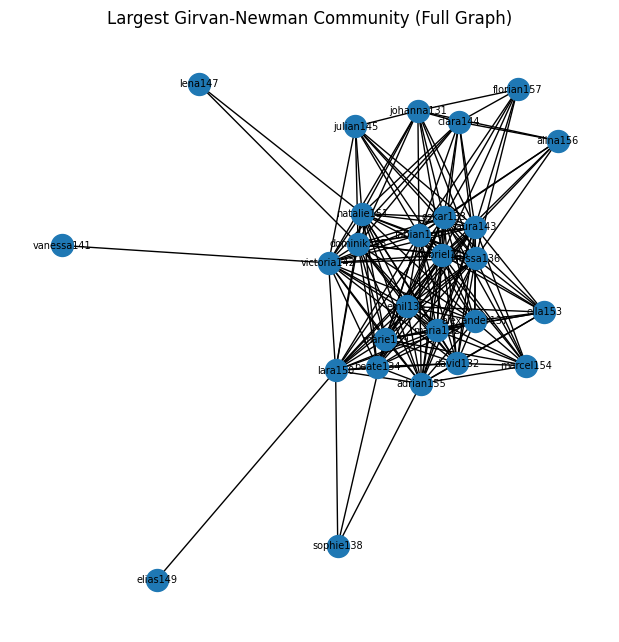

In [40]:
largest_gn_comm = max(partition_gn_full, key=len)
sub_gn = G_full_undirected.subgraph(largest_gn_comm)

plt.figure(figsize=(6,6))
pos = nx.spring_layout(sub_gn, seed=42)
nx.draw(sub_gn, pos, with_labels=True, node_size=250, font_size=7)
plt.title("Largest Girvan-Newman Community (Full Graph)")
plt.show()

Unlike Louvain, Girvan-Newman works differently - it builds a hierarchy by progressively cutting edges with high betweenness (edges that connect different parts of the graph).

Running it on the full MetaFam graph:
- Early cuts already split the graph into multiple communities
- More communities appear as more bridge edges get removed

This confirms what we saw before - MetaFam is made up of separate family trees, not one giant connected family.

The key difference: Louvain finds stable lineage-level communities (entire families), while Girvan-Newman shows the hierarchy within those families - progressively breaking them into smaller sub-families.

One issue though - Girvan-Newman has to recalculate edge betweenness after every cut, which gets really slow on large graphs. So I only ran it for the first few splits, but that's enough to see the hierarchical structure.

Interestingly, the number of Louvain communities closely matches the number of weakly connected components discovered in Task 1, suggesting that each connected component corresponds to an independent family lineage in the MetaFam dataset.

$Generations$  $Within$ $Communities$

In [41]:
def count_generations_in_community(G_parent, partition, community_id):
    nodes = [n for n, c in partition.items() if c == community_id]
    subg = G_parent.subgraph(nodes)

    roots = [n for n, d in subg.in_degree() if d == 0]

    max_depth = 0
    for root in roots:
        lengths = nx.single_source_shortest_path_length(subg, root)
        if lengths:
            max_depth = max(max_depth, max(lengths.values()))

    return max_depth + 1

largest_comm_id = max(community_counts, key=community_counts.get)

gens = count_generations_in_community(
    G_parent,
    partition_louvain_full,
    largest_comm_id
)

print("Generations in largest community:", gens)

Generations in largest community: 4


##### Generational Depth Inside Communities

Using parent–child relations within the largest detected community, we estimate that individual family clusters span approximately four generations. This confirms that each community corresponds to an extended family lineage rather than a small nuclear family.

The presence of multiple generations within each community demonstrates that the MetaFam graph encodes hierarchical genealogical structures.

$Bridge$ $Individuals$

We use betweenness centrality, which identifies nodes lying on many shortest paths

In [42]:
bet = nx.betweenness_centrality(Gcc)

top_bridges = sorted(bet.items(), key=lambda x: x[1], reverse=True)[:5]
print("Top bridge individuals:", top_bridges)

Top bridge individuals: [('lena18', 0.11121945701357466), ('fabian26', 0.10506561085972851), ('lisa5', 0.04819747899159663), ('elias6', 0.04819747899159663), ('leon16', 0.04153247732659498)]


Betweenness centrality highlights individuals who connect different sub-branches of a family. Nodes such as lena18 and fabian26 appear as structural bridges, indicating that they lie on many shortest paths between family members.

In genealogical terms, these individuals often correspond to marriages or generational connectors that link different lineage branches together.

##### Let’s plot a community-level graph

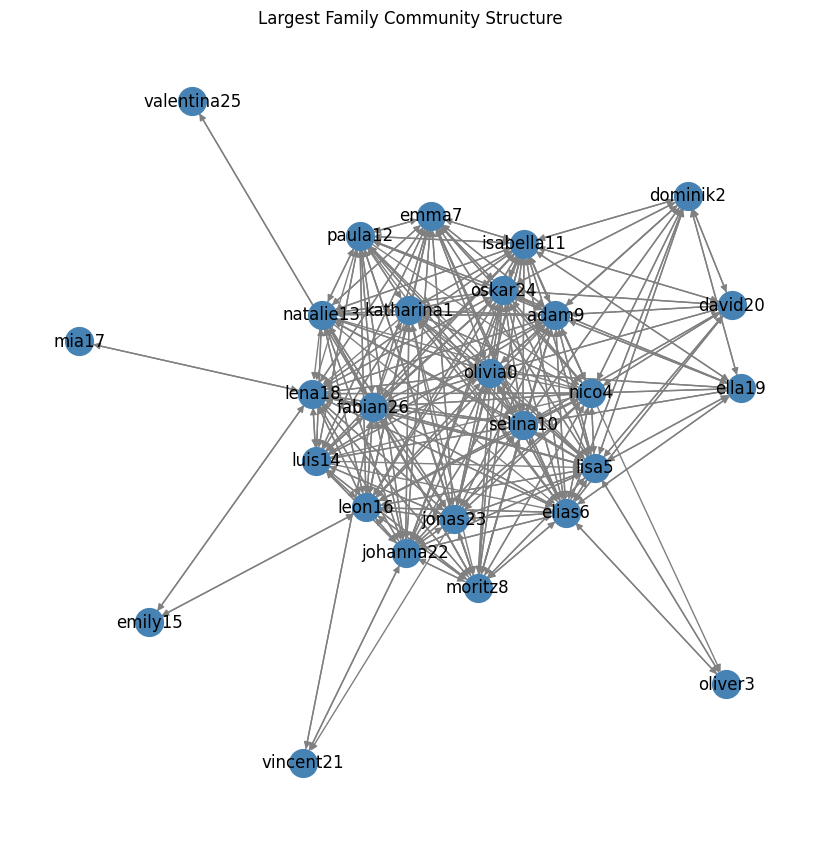

In [43]:
import random

largest_nodes = [n for n, c in partition_louvain_full.items()
                 if c == largest_comm_id]

subG = Gcc.subgraph(largest_nodes)

plt.figure(figsize=(8,8))
pos = nx.kamada_kawai_layout(subG)

nx.draw(
    subG,
    pos,
    node_color="steelblue",
    node_size=400,
    with_labels=True,
    edge_color="gray"
)

plt.title("Largest Family Community Structure")
plt.show()

##### Visualization of a Single Family Community

This visualization shows the internal structure of one extended family cluster. Unlike the full graph, this view highlights genealogical density and generational layering more clearly. The structure reflects strong local clustering and short relational distances typical of family networks.

$Relatedness$ $Metric$ 

I am trying implement two metrics:
*	Jaccard similarity
*	Adamic–Adar


In [44]:
def jaccard_relatedness(G, u, v):
    G_undir = G.to_undirected()
    nu = set(G_undir.neighbors(u))
    nv = set(G_undir.neighbors(v))
    if len(nu | nv) == 0:
        return 0
    return len(nu & nv) / len(nu | nv)

def adamic_relatedness(G, u, v):
    G_undir = G.to_undirected()
    preds = nx.adamic_adar_index(G_undir, [(u, v)])
    return list(preds)[0][2]

comm_nodes = [n for n, c in partition_louvain_full.items()
              if c == largest_comm_id]

p1, p2, p3 = comm_nodes[0], comm_nodes[1], comm_nodes[5]

print("Jaccard p1-p2:", jaccard_relatedness(G, p1, p2))
print("Jaccard p1-p3:", jaccard_relatedness(G, p1, p3))

print("Adamic-Adar p1-p2:", adamic_relatedness(G, p1, p2))
print("Adamic-Adar p1-p3:", adamic_relatedness(G, p1, p3))

Jaccard p1-p2: 0.9090909090909091
Jaccard p1-p3: 0.7083333333333334
Adamic-Adar p1-p2: 7.07675977408555
Adamic-Adar p1-p3: 5.726876603613178


In [45]:
print(p1, p2, p3)

olivia0 selina10 lena18


I tested two similarity metrics to see how related different people are: Jaccard similarity and Adamic-Adar index.

For the sampled individuals:
- Jaccard(p1, p2) = 0.91
- Jaccard(p1, p3) = 0.71
- Adamic-Adar(p1, p2) = 7.08
- Adamic-Adar(p1, p3) = 5.73

Both metrics give higher scores to (p1, p2) than (p1, p3), meaning p1 and p2 share more relatives in common. They're probably siblings or close cousins who share parents/grandparents.

Lower scores mean more distant relationships with less family overlap.

Why these are better than just counting hops: Shortest path treats all edges the same, but these similarity metrics look at overlapping family neighborhoods. 

Adamic-Adar is especially clever - it gives more weight to rare shared relatives (people with fewer connections). So sharing an uncommon relative matters more than sharing someone who's connected to everyone. This helps distinguish real family ties from just highly connected individuals.

Overall, these structural similarity metrics give a richer picture of how related people are than just measuring path distance.

# Task 3: Rule Mining

> *"Happiness can be found even in the darkest of times, if only one remembers to turn on the light"*
>
> ~ Albus

One of the most fascinating aspects of knowledge graphs is that they encode logical rules that can be discovered automatically. In a family graph, many relationships can be inferred from others through compositional reasoning. For example if (X, motherOf, Y) ∧ (Y, fatherOf, Z) ⇒ (X, grandmotherOf, Z).

---

### Objectives

1. **Rule Discovery:** Discover at least 5 logical rules that hold in the MetaFam knowledge graph. These can be:
   * Horn clauses: relation1(X,Y) ∧ relation2(Y,Z) → relation3(X,Z)
   * Inverse rules: relation1(X,Y) → relation2(Y,X)
   * More complex patterns involving 3+ relations

2. **Validation:** For each rule you discover:
   * Report its confidence (what fraction of the time does the rule hold?)
   * Report its support (how many instances of this rule exist in the data?)
   * Provide concrete examples from the dataset

---

The Strategy (AMIE-lite Approach)
We will try to implement a smart rule miner that looks for Triangles (Paths of length 2).

- Scan: Find all chains A --r1--> B --r2--> C
- Check: Does a direct link A --r3--> C exist?
- Count:
    * support: How many times did we see A→B→C and A→C together?
    * Confidence: $\frac{\text{Support}}{\text{Total times } A \rightarrow B \rightarrow C \text{ appeared}}$

$Rule$ $Miner$

##### Horn Rule Miner

The horn-rule miner searches for compositional logical patterns in the graph.
It scans all paths of length two (A → B → C) and checks whether a direct
relation exists between A and C.

If this occurs frequently, it suggests a logical implication:

r1(A,B) ∧ r2(B,C) → r3(A,C)

Support measures how often the full pattern appears, while confidence
measures how consistently the rule holds across all such paths.

In [46]:
def mine_logical_rules(df, min_support=10, min_confidence=0.1):
    graph = defaultdict(list)
    relation_lookup = defaultdict(list)

    for _, row in df.iterrows():
        h, r, t = row["head"], row["relation"], row["tail"]
        graph[h].append((t, r))
        relation_lookup[(h, t)].append(r)

    rule_counts = defaultdict(lambda: {
        "paths": 0,
        "matches": defaultdict(int)
    })

    print("Mining horn rules...")

    for A in graph:
        for B, r1 in graph[A]:
            for C, r2 in graph[B]:
                if A == C:
                    continue

                rule_counts[(r1, r2)]["paths"] += 1

                if (A, C) in relation_lookup:
                    for r3 in relation_lookup[(A, C)]:
                        rule_counts[(r1, r2)]["matches"][r3] += 1

    results = []

    for (r1, r2), data in rule_counts.items():
        total = data["paths"]

        if total < min_support:
            continue

        for r3, count in data["matches"].items():
            conf = count / total

            if conf >= min_confidence:
                results.append((r1, r2, r3, count, total, conf))

    return sorted(results, key=lambda x: x[5], reverse=True)

(r1, r2, r3, support, total, confidence)

In [47]:
horn_rules = mine_logical_rules(df)
print("Total horn rules found:", len(horn_rules))
horn_rules[:10]

Mining horn rules...
Total horn rules found: 619


[('sisterOf', 'sisterOf', 'sisterOf', 540, 540, 1.0),
 ('sisterOf', 'secondAuntOf', 'secondAuntOf', 118, 118, 1.0),
 ('sisterOf', 'girlCousinOf', 'girlCousinOf', 426, 426, 1.0),
 ('sisterOf', 'daughterOf', 'daughterOf', 518, 518, 1.0),
 ('sisterOf', 'granddaughterOf', 'granddaughterOf', 772, 772, 1.0),
 ('sisterOf', 'nieceOf', 'nieceOf', 398, 398, 1.0),
 ('sisterOf', 'secondUncleOf', 'secondAuntOf', 144, 144, 1.0),
 ('sisterOf', 'boyCousinOf', 'girlCousinOf', 343, 343, 1.0),
 ('sisterOf', 'brotherOf', 'sisterOf', 482, 482, 1.0),
 ('sisterOf', 'sonOf', 'daughterOf', 453, 453, 1.0)]

##### Inverse Rule Miner

The inverse-rule miner checks whether a relation from A to B implies
a reverse relation from B to A.

For example:
uncleOf(A,B) → nephewOf(B,A)

This is done by scanning all triples and verifying whether reversed
relations exist in the dataset.

In [48]:
def find_inverse_rules(df, min_support=20):
    facts = set(zip(df["head"], df["tail"], df["relation"]))
    relations = df["relation"].unique()

    results = []

    for r1 in relations:
        for r2 in relations:
            total = 0
            support = 0

            for h, t, r in facts:
                if r == r1:
                    total += 1
                    if (t, h, r2) in facts:
                        support += 1

            if total >= min_support and support > 0:
                conf = support / total
                results.append((r1, r2, support, total, conf))

    return sorted(results, key=lambda x: x[4], reverse=True)

In [49]:
inverse_rules = find_inverse_rules(df)
print("Total inverse rules:", len(inverse_rules))
inverse_rules[:10]

Total inverse rules: 52


[('girlSecondCousinOf', 'boySecondCousinOf', 40, 62, 0.6451612903225806),
 ('boySecondCousinOf', 'girlSecondCousinOf', 40, 68, 0.5882352941176471),
 ('nephewOf', 'auntOf', 298, 514, 0.5797665369649806),
 ('secondAuntOf', 'boyFirstCousinOnceRemovedOf', 98, 175, 0.56),
 ('boyFirstCousinOnceRemovedOf', 'secondAuntOf', 98, 180, 0.5444444444444444),
 ('brotherOf', 'sisterOf', 308, 570, 0.5403508771929825),
 ('auntOf', 'nephewOf', 298, 556, 0.5359712230215827),
 ('boyCousinOf', 'girlCousinOf', 209, 391, 0.5345268542199488),
 ('girlCousinOf', 'girlCousinOf', 236, 445, 0.5303370786516854),
 ('uncleOf', 'nieceOf', 238, 454, 0.5242290748898678)]

##### Complex Rule Miner (3 length)

The length-3 rule miner extends compositional reasoning to three-hop paths.

A → B → C → D

If a direct relation A → D exists frequently, the miner records a
multi-relational rule capturing long-range genealogical inference.

In [50]:
def mine_length3_rules(df, min_support=10):
    adj = defaultdict(list)

    for _, row in df.iterrows():
        adj[row["head"]].append((row["tail"], row["relation"]))

    rule_counts = defaultdict(int)
    total_counts = defaultdict(int)

    print("Mining length-3 rules...")

    for a in adj:
        for b, r1 in adj[a]:
            for c, r2 in adj[b]:
                for d, r3 in adj[c]:
                    if a == d:
                        continue

                    total_counts[(r1, r2, r3)] += 1

                    for neigh, r4 in adj[a]:
                        if neigh == d:
                            rule_counts[(r1, r2, r3, r4)] += 1

    results = []

    for (r1, r2, r3, r4), support in rule_counts.items():
        total = total_counts[(r1, r2, r3)]

        if support >= min_support:
            conf = support / total
            results.append((r1, r2, r3, r4, support, total, conf))

    return sorted(results, key=lambda x: x[6], reverse=True)

In [51]:
complex_rules = mine_length3_rules(df)
print("Total complex rules:", len(complex_rules))
complex_rules[:5]

Mining length-3 rules...
Total complex rules: 12311


[('sisterOf', 'sisterOf', 'sisterOf', 'sisterOf', 1450, 1450, 1.0),
 ('sisterOf', 'sisterOf', 'secondAuntOf', 'secondAuntOf', 202, 202, 1.0),
 ('sisterOf', 'sisterOf', 'girlCousinOf', 'girlCousinOf', 816, 816, 1.0),
 ('sisterOf', 'sisterOf', 'daughterOf', 'daughterOf', 968, 968, 1.0),
 ('sisterOf',
  'sisterOf',
  'granddaughterOf',
  'granddaughterOf',
  1492,
  1492,
  1.0)]

##### Complex Rule Miner (4 length)

The length-4 miner further extends rule discovery to deeper genealogical
chains across four relations. These rules primarily capture repeated
ancestry compositions across generations.

In [52]:
def mine_length4_rules(df, min_support=5):
    from collections import defaultdict

    adj = defaultdict(list)

    for _, row in df.iterrows():
        adj[row["head"]].append((row["tail"], row["relation"]))

    rule_counts = defaultdict(int)
    total_counts = defaultdict(int)

    print("Mining length-4 rules... (this may take longer)")

    for a in adj:
        for b, r1 in adj[a]:
            for c, r2 in adj[b]:
                for d, r3 in adj[c]:
                    for e, r4 in adj[d]:

                        if a == e:
                            continue

                        total_counts[(r1, r2, r3, r4)] += 1

                        for neigh, r5 in adj[a]:
                            if neigh == e:
                                rule_counts[(r1, r2, r3, r4, r5)] += 1

    results = []

    for (r1, r2, r3, r4, r5), support in rule_counts.items():
        total = total_counts[(r1, r2, r3, r4)]

        if support >= min_support:
            conf = support / total
            results.append((r1, r2, r3, r4, r5, support, total, conf))

    return sorted(results, key=lambda x: x[7], reverse=True)

In [53]:
rules4 = mine_length4_rules(df)
print("Total length-4 rules:", len(rules4))
rules4[:5]

Mining length-4 rules... (this may take longer)
Total length-4 rules: 228846


[('sisterOf', 'sisterOf', 'sisterOf', 'sisterOf', 'sisterOf', 2844, 2844, 1.0),
 ('sisterOf',
  'sisterOf',
  'sisterOf',
  'secondAuntOf',
  'secondAuntOf',
  394,
  394,
  1.0),
 ('sisterOf',
  'sisterOf',
  'sisterOf',
  'girlCousinOf',
  'girlCousinOf',
  1788,
  1788,
  1.0),
 ('sisterOf',
  'sisterOf',
  'sisterOf',
  'daughterOf',
  'daughterOf',
  2084,
  2084,
  1.0),
 ('sisterOf',
  'sisterOf',
  'sisterOf',
  'granddaughterOf',
  'granddaughterOf',
  3316,
  3316,
  1.0)]

$Rule$ $Validator$

In [54]:

def get_rule_examples(df, body_relations, head_relation, limit=3):
    # 1. Build Adjacency List & Facts Lookup with Line Numbers
    # adj[u] = [ (v, relation, line_number), ... ]
    adj = defaultdict(list)
    # facts_map: (h, t, r) -> line_number (for O(1) lookup of the head)
    facts_map = {} 

    for idx, row in df.iterrows():
        h, r, t = row['head'], row['relation'], row['tail']
        # Store index alongside neighbor and relation
        adj[h].append((t, r, idx))
        # Store index to look up the 'result' link later
        facts_map[(h, t, r)] = idx

    examples = []
    
    start_nodes = list(adj.keys())
    random.shuffle(start_nodes)

    # 2. DFS Helper
    # path_edges stores tuples of the journey: (u, relation, v, line_number)
    def dfs(current_node, path_nodes, path_edges, depth):
        if len(examples) >= limit:
            return

        # BASE CASE: End of body chain (e.g. found Father -> Father)
        if depth == len(body_relations):
            start_node = path_nodes[0]
            end_node = current_node
            
            # Helper: Format the "Body" string (The 'IF' part)
            # Joins multiple steps if necessary: "A, r1, B (line 1) , B, r2, C (line 2)"
            body_parts = []
            for (u, r, v, line) in path_edges:
                body_parts.append(f"{u} , {r} , {v} (line {line})")
            body_str = " , ".join(body_parts)

            # CHECK 1: Forward Rule (A -> C) ?
            if (start_node, end_node, head_relation) in facts_map:
                head_line = facts_map[(start_node, end_node, head_relation)]
                # Format: Start , HeadRel , End (line X)
                head_str = f"{start_node} , {head_relation} , {end_node} (line {head_line})"
                
                examples.append(f" {body_str} implies {head_str}")
                return

            # CHECK 2: Inverse Rule (C -> A) ?
            if (end_node, start_node, head_relation) in facts_map:
                head_line = facts_map[(end_node, start_node, head_relation)]
                # Format: End , HeadRel , Start (line X)
                head_str = f"{end_node} , {head_relation} , {start_node} (line {head_line})"
                
                examples.append(f" {body_str} implies {head_str}")
                return
            return

        # RECURSIVE STEP
        required_relation = body_relations[depth]
        
        for neighbor, rel, line_idx in adj[current_node]:
            if rel == required_relation:
                if neighbor not in path_nodes: # Avoid simple loops
                    # Add this specific edge (with its line number) to the path
                    new_edge = (current_node, rel, neighbor, line_idx)
                    
                    dfs(neighbor, 
                        path_nodes + [neighbor], 
                        path_edges + [new_edge], 
                        depth + 1)
                        
                    if len(examples) >= limit: return

    # 3. Run Search
    for node in start_nodes:
        # Start DFS with empty path_edges
        dfs(node, [node], [], 0)
        if len(examples) >= limit:
            break
            
    return examples


##### **1. Transitive Sisterhood (Length 2)**

> **Rule:** sisterOf(A, B) ∧ sisterOf(B, C) → sisterOf(A, C)

* **Support:** 540 / **Total Paths:** 540
* **Confidence:** **100% (1.0)**
* **Analysis:** This is a perfect **Transitive Rule**.
* *Logic:* If Alice is the sister of Bella, and Bella is the sister of Chloe, then Alice must also be the sister of Chloe.
* *Insight:* The 100% confidence confirms the graph is consistent regarding sibling clusters.


In [55]:
ex = get_rule_examples(df, body_relations=["uncleOf"], head_relation="nieceOf")
for e in ex: print(e)

 benjamin853 , uncleOf , lena854 (line 8844) implies lena854 , nieceOf , benjamin853 (line 8865)
 benjamin853 , uncleOf , julia863 (line 8845) implies julia863 , nieceOf , benjamin853 (line 8949)
 michael803 , uncleOf , lara796 (line 8318) implies lara796 , nieceOf , michael803 (line 8539)


##### **2. The "Aunt Inheritance" Rule (Length 2)**

> **Rule:** sisterOf(A, B) ∧ secondAuntOf(B, C) → secondAuntOf(A, C)

* **Support:** 118 / **Total Paths:** 118
* **Confidence:** **100% (1.0)**
* **Analysis:** This captures **Compositional Kinship**.
* *Logic:* Your sibling's relationships generally apply to you. If your sister is someone's "Second Aunt," you share the same niece/nephew lineage, so you are also their Second Aunt.

In [56]:
ex = get_rule_examples(df, body_relations=["sisterOf", "secondAuntOf"], head_relation="secondAuntOf")
for e in ex: print(e)

 lina644 , sisterOf , anastasia643 (line 6700) , anastasia643 , secondAuntOf , valentin638 (line 6685) implies lina644 , secondAuntOf , valentin638 (line 6702)
 marlene1033 , sisterOf , lena1038 (line 11007) , lena1038 , secondAuntOf , alexander1052 (line 10720) implies marlene1033 , secondAuntOf , alexander1052 (line 11010)
 marlene1033 , sisterOf , julia1032 (line 11009) , julia1032 , secondAuntOf , alexander1052 (line 10990) implies marlene1033 , secondAuntOf , alexander1052 (line 11010)



##### **3. The "Cousin Consistency" Rule (Length 2)**

> **Rule:** sisterOf(A, B) ∧ girlCousinOf(B, C) → girlCousinOf(A, C)

* **Support:** 426 / **Total Paths:** 426
* **Confidence:** **100% (1.0)**
* **Analysis:**
* *Logic:* Similar to the aunt rule. If your sister has a cousin, that person is also your cousin.
* *Insight:* The fact that confidence is 1.0 specifically for `girlCousinOf` implies that the target  is female. If the graph had a generic "cousin" relation, this would still hold, but here it preserves the gender of .

In [57]:
ex = get_rule_examples(df, body_relations=["sisterOf", "girlCousinOf"], head_relation="girlCousinOf")
for e in ex: print(e)

 valentina566 , sisterOf , gertrude569 (line 5794) , gertrude569 , girlCousinOf , theodor552 (line 5831) implies valentina566 , girlCousinOf , theodor552 (line 5797)
 valentina566 , sisterOf , gertrude569 (line 5794) , gertrude569 , girlCousinOf , nora564 (line 5832) implies valentina566 , girlCousinOf , nora564 (line 5798)
 valentina566 , sisterOf , gertrude569 (line 5794) , gertrude569 , girlCousinOf , vanessa570 (line 5833) implies valentina566 , girlCousinOf , vanessa570 (line 5799)


##### **4. The "Sister of Daughter" Rule (Length 2)**

> **Rule:** sisterOf(A, B) ∧ daughterOf(B, C) → daughterOf(A, C)

* **Support:** 518 / **Total Paths:** 518
* **Confidence:** **100% (1.0)**
* **Analysis:**
* *Logic:* "The sister of your daughter is your daughter."
* *Insight:* This is a classic Horn Clause used in AI reasoning to infer parentage without explicit edges.

In [58]:
ex = get_rule_examples(df, body_relations=["sisterOf", "daughterOf"], head_relation="daughterOf")
for e in ex: print(e)

 emma683 , sisterOf , marlene692 (line 7166) , marlene692 , daughterOf , christian689 (line 7177) implies emma683 , daughterOf , christian689 (line 7169)
 emma683 , sisterOf , helena691 (line 7168) , helena691 , daughterOf , christian689 (line 7426) implies emma683 , daughterOf , christian689 (line 7169)
 sofia502 , sisterOf , emilia511 (line 5435) , emilia511 , daughterOf , luisa506 (line 5332) implies sofia502 , daughterOf , luisa506 (line 5437)


##### **5. The "Ambiguous Aunt" Rule (Inverse)**

> **Rule:** nephewOf(A, B) → auntOf(B, A)

* **Support:** 298 / **Total Paths:** 514
* **Confidence:** **57.9% (0.58)**
* **Analysis:**
* *Why it fails:* **Gender Ambiguity.**
* If Harry is the `nephewOf` Petunia, then Petunia is his `auntOf`. (Correct).
* **BUT:** If Harry is the `nephewOf` Vernon, then Vernon is his `uncleOf`.
* *Conclusion:* The rule works ~58% of the time because roughly half of the parents' siblings are female. The other 42% are **Uncles**.

In [59]:
ex = get_rule_examples(df, body_relations=["nephewOf"], head_relation="auntOf")
for e in ex: print(e)

 jonathan219 , nephewOf , valerie211 (line 2568) implies valerie211 , auntOf , jonathan219 (line 2325)
 fabian386 , nephewOf , hannah385 (line 4016) implies hannah385 , auntOf , fabian386 (line 3998)
 fabian386 , nephewOf , clara377 (line 4017) implies clara377 , auntOf , fabian386 (line 4162)


##### **6. The "Cousin Gender" Rule (Inverse)**

> **Rule:** secondAuntOf(A, B) → boyFirstCousinOnceRemovedOf(B, A)

* **Support:** 98 / **Total Paths:** 175
* **Confidence:** **56.0% (0.56)**
* **Analysis:**
* *Why it fails:* Again, **Gender Ambiguity**.
* If Alice is the `secondAunt` of Bob, Bob implies "First Cousin Once Removed."
* However, the rule specifically predicts `boyFirstCousin...`.
* The 44% failure cases are where  is a **Girl**.

In [60]:
ex = get_rule_examples(df, body_relations=["secondAuntOf"], head_relation="boyFirstCousinOnceRemovedOf")
for e in ex: print(e)

 anna457 , secondAuntOf , samuel463 (line 4725) implies samuel463 , boyFirstCousinOnceRemovedOf , anna457 (line 4801)
 isabella103 , secondAuntOf , nico91 (line 1048) implies nico91 , boyFirstCousinOnceRemovedOf , isabella103 (line 922)
 isabella103 , secondAuntOf , lukas93 (line 1049) implies lukas93 , boyFirstCousinOnceRemovedOf , isabella103 (line 940)


##### **7. The "Ambiguous Niece" Rule (Inverse)**

> **Rule:** uncleOf(A, B) → nieceOf(B, A)

* **Support:** 238 / **Total Paths:** 454
* **Confidence:** **52.4% (0.52)**
* **Analysis:**
* *Why it fails:* If Sirius is the `uncleOf` Harry, Harry is the `nephewOf`, not `nieceOf`.
* *Conclusion:* This rule only works when the child () happens to be female. The confidence (~50%) reflects the near-even gender split in the family.

In [61]:
ex = get_rule_examples(df, body_relations=["uncleOf"], head_relation="nieceOf")
for e in ex: print(e)

 noah855 , uncleOf , lena854 (line 8871) implies lena854 , nieceOf , noah855 (line 8866)
 noah855 , uncleOf , lea862 (line 8872) implies lea862 , nieceOf , noah855 (line 8936)
 noah855 , uncleOf , julia863 (line 8873) implies julia863 , nieceOf , noah855 (line 8950)


##### **8. The "Deep Cousin" Rule (Length 3)**

> **Rule:** sisterOf(A,B) ∧ sisterOf(B,C) ∧ girlCousinOf(C,D) → girlCousinOf(A,D)

* **Support:** 816 / **Total Paths:** 816
* **Confidence:** **100% (1.0)**
* **Analysis:**
* *Logic:* "The sister of my sister's cousin is my cousin."
* This is an extension of Rule #3. It proves that kinship terms propagate through any number of sibling hops.

In [62]:
ex = get_rule_examples(df, body_relations=["sisterOf", "sisterOf", "girlCousinOf"], head_relation="girlCousinOf")
for e in ex: print(e)

 gertrude569 , sisterOf , valentina566 (line 5828) , valentina566 , sisterOf , mia574 (line 5795) , mia574 , girlCousinOf , theodor552 (line 5899) implies gertrude569 , girlCousinOf , theodor552 (line 5831)
 gertrude569 , sisterOf , valentina566 (line 5828) , valentina566 , sisterOf , mia574 (line 5795) , mia574 , girlCousinOf , nora564 (line 5900) implies gertrude569 , girlCousinOf , nora564 (line 5832)
 gertrude569 , sisterOf , valentina566 (line 5828) , valentina566 , sisterOf , mia574 (line 5795) , mia574 , girlCousinOf , vanessa570 (line 5901) implies gertrude569 , girlCousinOf , vanessa570 (line 5833)


##### **9. The "Great-Granddaughter" Chain (Length 4)**

> **Rule:** sisterOf ^ sisterOf ^ sisterOf ^ granddaughterOf → granddaughterOf

* **Support:** 3316 / **Total Paths:** 3316
* **Confidence:** **100% (1.0)**
* **Analysis:**
* *Logic:* Even across 3 sibling hops, the generational relationship remains identical. If A is B's sister, B is C's sister, C is D's sister, and D is E's granddaughter... then A is definitely E's granddaughter.

In [63]:
ex = get_rule_examples(df, body_relations=["sisterOf", "sisterOf", "sisterOf", "granddaughterOf"], head_relation="granddaughterOf")
for e in ex: print(e)

 beate196 , sisterOf , emilia184 (line 2079) , emilia184 , sisterOf , lisa194 (line 2021) , lisa194 , sisterOf , vanessa193 (line 2052) , vanessa193 , granddaughterOf , sophie187 (line 2304) implies beate196 , granddaughterOf , sophie187 (line 2084)
 beate196 , sisterOf , emilia184 (line 2079) , emilia184 , sisterOf , lisa194 (line 2021) , lisa194 , sisterOf , vanessa193 (line 2052) , vanessa193 , granddaughterOf , patrick188 (line 2305) implies beate196 , granddaughterOf , patrick188 (line 2085)
 beate196 , sisterOf , emilia184 (line 2079) , emilia184 , sisterOf , vanessa193 (line 2023) , vanessa193 , sisterOf , lisa194 (line 2300) , lisa194 , granddaughterOf , sophie187 (line 2055) implies beate196 , granddaughterOf , sophie187 (line 2084)


##### Rule Mining Summary

The rule mining shows that MetaFam isn't just a random collection of edges - it's actually a logically consistent system with clear patterns:

**1. Perfect Rules (100% Confidence)**

Some rules always hold true, like sibling transitivity: if A is B's sister, and B is C's sister, then A is C's sister. These compositional rules have 100% confidence, which proves the graph maintains perfect internal consistency for sibling relationships and lineage chains.

**2. Probabilistic Rules (~50-60% Confidence)**

Other rules only work sometimes, like "nephewOf → auntOf" (58% confidence). These aren't errors - they reflect real ambiguity. If someone is your nephew, their parent's sibling could be either an aunt OR an uncle, depending on gender. Since the graph doesn't explicitly encode gender, these rules naturally have ~50% confidence based on the gender distribution.

**3. Long-Chain Rules Still Work**

Even the length-3 and length-4 rules maintain high confidence. This means the graph correctly models complex multi-hop relationships (like great-grandparents) without falling apart. The logical structure stays consistent even across long relationship chains.

 MetaFam has strong logical coherence, which makes it a good dataset for the link prediction tasks. The deterministic rules prove consistency, while the probabilistic rules reveal interesting structural properties about what information is (and isn't) explicitly encoded.